<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_1_Intro_to_DS_and_Naive_Bayes/Projects/Instructions/Project.1-Transactions/Project.1-Pass-07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project.1_Pass-07, Transaction Data




## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

### Business Problem
We want to predict whether or not a future customer will make a transaction based on their transaction data. The goal might be to increase customer transactions by sending targeted ads/deals to customers who are not likely to make a transaction on a given day.

### Data Science Problem
Supervised binary classification problem.

## Data Collection/Sources


### Load Pandas, Numpy, and Matplotlib modules

In [1]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

### Load data Train.csv from AWS S3[link text](https://)

In [2]:
# Load the big dataset Train.big.csv from AWS S3
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'
url

df = pd.read_csv(
    url,
    usecols=range(15),
    nrows=10_000,
)

df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,train_9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,9996,train_9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,9997,train_9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,9998,train_9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Look at the first few rows
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.476,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Look at the last few rows
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
9995,9995,train_9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,9996,train_9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,9997,train_9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,9998,train_9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,9999,train_9999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Data Cleaning


### Summary Meta-Data

In [5]:
# Shape of the dataframe
df.shape

(10000, 15)

In [6]:
# Size of the dataframe
df.size

150000

In [7]:
# Display meta-data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  10000 non-null  int64  
 1   ID_code     10000 non-null  object 
 2   target      1686 non-null   float64
 3   var_0       1686 non-null   float64
 4   var_1       1686 non-null   float64
 5   var_2       1686 non-null   float64
 6   var_3       0 non-null      float64
 7   var_4       1686 non-null   float64
 8   var_5       0 non-null      float64
 9   var_6       0 non-null      float64
 10  var_7       1686 non-null   float64
 11  var_8       1686 non-null   float64
 12  var_9       0 non-null      float64
 13  var_10      0 non-null      float64
 14  var_11      0 non-null      float64
dtypes: float64(13), int64(1), object(1)
memory usage: 1.1+ MB


### Summary Statistics

In [8]:
# Display summary statistics
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
count,10000.00000,1686.000000,1686.000000,1686.000000,1686.000000,0.0,1686.000000,0.0,0.0,1686.000000,1686.000000,0.0,0.0,0.0
mean,4999.50000,0.098458,7.493109,15.840630,12.667966,NaN,-0.461214,NaN,NaN,1.276329,6.812313,NaN,NaN,NaN
std,2886.89568,0.298021,3.090435,3.086651,4.187706,NaN,6.014515,NaN,NaN,5.103567,0.374905,NaN,NaN,NaN
min,0.00000,0.000000,-0.101600,7.700200,3.218700,NaN,-16.855000,NaN,NaN,-11.731000,5.688300,NaN,NaN,NaN
25%,2499.75000,0.000000,5.174825,13.739200,9.601600,NaN,-4.893675,NaN,NaN,-2.458950,6.559500,NaN,NaN,NaN
50%,4999.50000,0.000000,7.379350,15.992700,12.478250,NaN,-0.190200,NaN,NaN,1.080350,6.795350,NaN,NaN,NaN
75%,7499.25000,0.000000,9.708875,18.155675,15.725050,NaN,3.730575,NaN,NaN,5.107175,7.071325,NaN,NaN,NaN
max,9999.00000,1.000000,16.716500,23.971700,24.828500,NaN,15.973100,NaN,NaN,17.441800,7.877900,NaN,NaN,NaN


### Data Types

In [9]:
# Display data types of columns
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,float64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64


### Nulls and Identifier Columns
Imputation required on account of the nulls.

#### NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

#### Target Value Counts

Binary numerical classification and nulls are present.

In [10]:
# Value_counts on target ; include nulls
df['target'].value_counts(dropna=False)

,count
target,
NaN,8314
0.0,1520
1.0,166


#### Normalize The Data

In [11]:
# Normalized value_counts on target ; include nulls
df['target'].value_counts(dropna=False, normalize=True)

,proportion
target,
NaN,0.8314
0.0,0.1520
1.0,0.0166


#### Nulls

In [12]:
# Look for nulls
df.isnull().sum().sort_values(ascending=False)

,0
var_3,10000
var_6,10000
var_11,10000
var_9,10000
var_10,10000
var_5,10000
var_0,8314
target,8314
var_4,8314
var_2,8314


#### Feature Columns

In [13]:
# Normalize the data to see proportion of nulls on features
df.drop(columns=['target']).isnull().mean().sort_values(ascending=False)

,0
var_3,1.0000
var_11,1.0000
var_9,1.0000
var_10,1.0000
var_6,1.0000
var_5,1.0000
var_0,0.8314
var_4,0.8314
var_2,0.8314
var_1,0.8314


#### Identifier Columns

In [14]:
# Number of unique elements in a column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,10000
ID_code,10000
var_4,1678
var_7,1677
var_0,1677
var_2,1672
var_1,1663
var_8,1596
target,2
var_3,0


### Backup #1

In [15]:
# Make backup
df_bak = df.copy()

In [36]:
# Restore from backup
df = df_bak.copy()

### Recommendations

#### Identifier Columns

Exclude columns 'Unnamed: 0' and 'ID_code'

In [37]:
# Drop the 'Unnamed: 0' and 'ID_code' columns
df = df.drop(columns=['Unnamed: 0','ID_code'])

In [38]:
# Verify
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Target Column with Null Counts

Remove rows with unknown target values

In [39]:
df = df.dropna(subset=['target'])

In [31]:
# Verify
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,NaN,-4.5570,NaN,NaN,-2.0199,6.4613,NaN,NaN,NaN
9982,0.0,7.4992,12.3931,15.6143,NaN,3.9159,NaN,NaN,-6.4257,6.4960,NaN,NaN,NaN
9983,0.0,3.6195,11.1681,6.0020,NaN,2.7570,NaN,NaN,-1.3041,7.3073,NaN,NaN,NaN
9993,0.0,6.6722,17.1154,9.2696,NaN,8.2625,NaN,NaN,4.0066,6.6464,NaN,NaN,NaN


#### Feature Columns with High Null Counts

Investigate usefullness and consider dropping or imputing

In [40]:
#See null counts in each of the var columns (exlude the identifier and target columns)
df.isnull().sum().sort_values(ascending=False)

,0
var_3,1686
var_9,1686
var_10,1686
var_6,1686
var_5,1686
var_11,1686
var_1,0
var_0,0
target,0
var_2,0


In [33]:
# Drop columns that contain exactly all null values (1686 nulls)
df = df.dropna(axis=1, thresh=1)

In [34]:
# Verify
df.isnull().sum().sort_values(ascending=False)

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0


#### Feature Columns with Low Null Counts

Consider some row removal or imputation

In [35]:
df.isnull().sum()

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0


#### Feature Columns with Medium Null Counts

Investigate before removing rows

In [ ]:
# No imputation needed

### Backup #2

In [41]:
# Make 2nd backup
df_bak_2 = df.copy()

In [42]:
# Restore from 2nd backup
df = df_bak_2.copy()

### Keep Only the Target and Features

In [43]:
# Select the target and features
df = df[['target'] + [f'var_{i}' for i in range(9)]]
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045
...,...,...,...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,NaN,-4.5570,NaN,NaN,-2.0199,6.4613
9982,0.0,7.4992,12.3931,15.6143,NaN,3.9159,NaN,NaN,-6.4257,6.4960
9983,0.0,3.6195,11.1681,6.0020,NaN,2.7570,NaN,NaN,-1.3041,7.3073
9993,0.0,6.6722,17.1154,9.2696,NaN,8.2625,NaN,NaN,4.0066,6.6464


Backup #3

In [25]:
# Make a backup
df_bak_3 = df.copy()

In [ ]:
# Restore from backup
df = df_bak_3.copy()

## Exploratory Data Analysis


### Normal Distribution of Features: Histogram & Box Plot

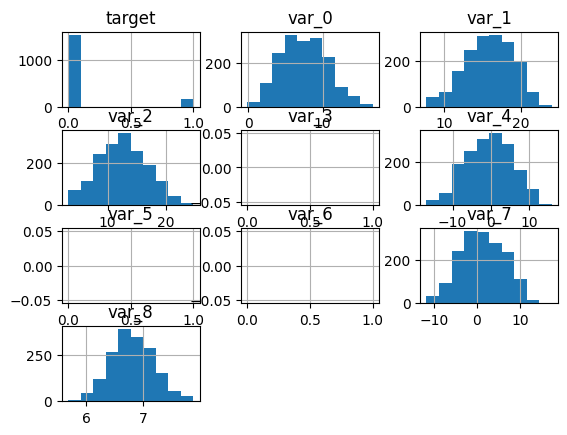

In [44]:
# Display a histogram
df.hist() ;

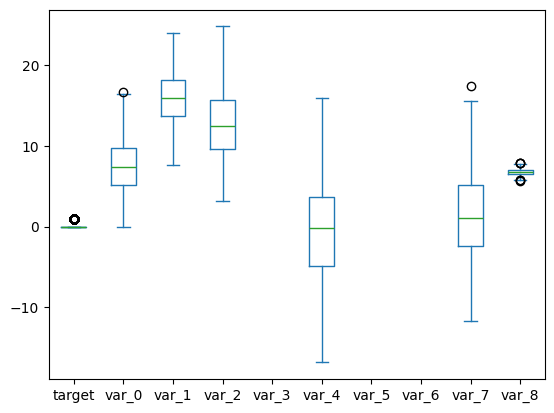

In [45]:
# Display a box and whisker plot
df.plot(kind='box') ;

### Correlation: Independence of Features

In [46]:
# Calculate a correlation matrix
iso_features = df[['target'] + [f'var_{i}' for i in range(9)]]

corr_mat = iso_features.corr()

corr_mat

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8
target,1.000000,0.037293,-0.026791,-0.041715,NaN,-0.038164,NaN,NaN,0.003941,0.021176
var_0,0.037293,1.000000,0.005254,-0.008940,NaN,-0.032564,NaN,NaN,0.019145,-0.004555
var_1,-0.026791,0.005254,1.000000,-0.006304,NaN,0.027493,NaN,NaN,0.033324,0.005790
var_2,-0.041715,-0.008940,-0.006304,1.000000,NaN,0.032350,NaN,NaN,0.015287,-0.007869
var_3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
var_4,-0.038164,-0.032564,0.027493,0.032350,NaN,1.000000,NaN,NaN,0.016244,-0.016298
var_5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
var_6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
var_7,0.003941,0.019145,0.033324,0.015287,NaN,0.016244,NaN,NaN,1.000000,-0.031002
var_8,0.021176,-0.004555,0.005790,-0.007869,NaN,-0.016298,NaN,NaN,-0.031002,1.000000


Text(0.5, 23.52222222222222, 'Features')

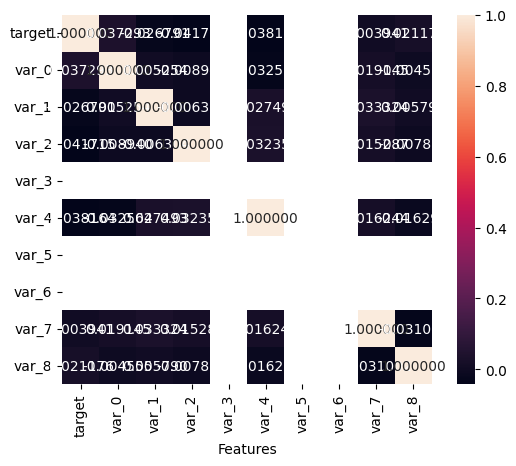

In [47]:
# Heatmap of the correlation matrix
sns.heatmap(
    corr_mat,
    square=True,
    annot=True,
    fmt='2f',
    cbar=True,
)

plt.xlabel('Features')
plt.xlabel('Features')

### Create Two Dataframes (Copies, Not Slices)
1. Successful Transactions
1. Unsuccessful Transactions

In [48]:
# Create a dataframe of successful transactions
successful_df = df[df['target'] == 1].copy()

# Create a dataframe of unsuccessful transactions
unsuccessful_df = df[df['target'] == 0].copy()

## Processing



### Single Cross Validation ( CV )

#### Two data sets with target and features

In [49]:
# Split data frame into target and features
target_col = 'target'
target = df[ target_col]
features = df.drop(columns=[target_col])

In [50]:
# Display the target
target

,target
3,0.0
5,0.0
11,0.0
15,0.0
19,0.0
...,...
9978,0.0
9982,0.0
9983,0.0
9993,0.0


In [51]:
# Display the features
features

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8
3,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760
5,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821
11,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144
15,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670
19,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045
...,...,...,...,...,...,...,...,...,...
9978,3.7065,12.2215,12.0781,NaN,-4.5570,NaN,NaN,-2.0199,6.4613
9982,7.4992,12.3931,15.6143,NaN,3.9159,NaN,NaN,-6.4257,6.4960
9983,3.6195,11.1681,6.0020,NaN,2.7570,NaN,NaN,-1.3041,7.3073
9993,6.6722,17.1154,9.2696,NaN,8.2625,NaN,NaN,4.0066,6.6464


#### Define an empty Gaussian Naïve Bayes model using Sklearn

In [52]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### Divide the two data sets you created in step 10 into training and testing subsets, i.e. train-test split.

In [53]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
     features,
     target,
     test_size=0.25
)

In [54]:
# Verify shape of each data set from Train Test Split
for i in [ X_train, X_test, y_train, y_test ]:
  print(i.shape)
  print(type(i))

(1264, 9)
<class 'pandas.core.frame.DataFrame'>
(422, 9)
<class 'pandas.core.frame.DataFrame'>
(1264,)
<class 'pandas.core.series.Series'>
(422,)
<class 'pandas.core.series.Series'>


#### Train ( fit ) the model using the training subset of the dataset.

In [55]:
# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

ValueError: Input X contains NaN.
GaussianNB does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

#### Test the model ( predict ) using the testing subset of the dataset.

In [ ]:
# Make predicitons using the model
pred_results = modelGNB.predict(X_test)
pred_results * 1000

array([0, 0, 0, ..., 0, 0, 0])

#### Calculate and report the accuracy.

In [ ]:
# Display accuracy
acc = metrics.accuracy_score( y_test,pred_results )
acc * 100

91.20888888888888

#### Present a confusion matrix and heatmap

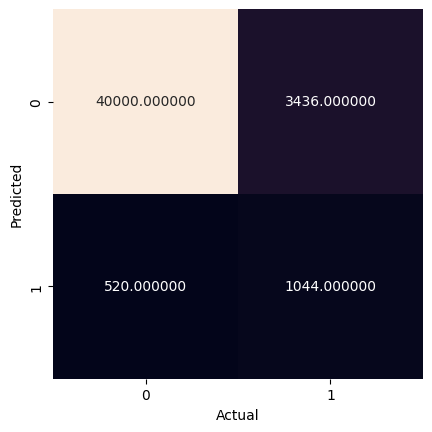

In [ ]:
# Display a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
)
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Present the results of a Classification Report (sklearn.metrics.classification_report).

In [ ]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95     40520
           1       0.67      0.23      0.35      4480

    accuracy                           0.91     45000
   macro avg       0.79      0.61      0.65     45000
weighted avg       0.90      0.91      0.89     45000



### Multiple Cross-Validation (CV)

In [ ]:
# Multiple CV loop
n = 100
results = np.zeros(n)

for i in range(n):
   X_train, X_test, y_train, y_test = train_test_split(
        features, target, test_size=0.25, random_state=None
)

# Create an empty GNB model
modelGNB = GaussianNB()

# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

# Make predicitons using the model
pred_results = modelGNB.predict(X_test)

# calculate the accuracy
results[i] = metrics.accuracy_score(y_test, pred_results)

results

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

### Accuracy Comparison
Accuracies are both 91% for single and multi CVs

In [ ]:
# Compare the accuracies by creating variables for each
acc_single_cv = acc
acc_multi_cv = results[i]

display('Single CV:', acc_single_cv)
display('Multi CV:', acc_multi_cv)

'Single CV:'

0.9120888888888888

'Multi CV:'

np.float64(0.9121777777777778)

### Balance Dataset

The training data is very skewed towards non-successful transactions (about 90% of the training data has ‘target’==0).

#### Remove enough non-successful transaction rows so that your remaining training data is 50%/50% split between successful and non-successful transactions.

In [ ]:
# Display value counts of the target
df['target'].value_counts()

,count
target,
0,161960
1,18040


In [ ]:
# Place minority class in one dataframe
successful_df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
13,1,16.3699,1.5934,16.7395,4.8222,8.6978,13.7999,2.7925,14.3984,19.4258,...,5.6656,3.5750,-2.2723,15.7383,8.5618,11.8982,7.4002,7.4031,4.3989,15.6064
29,1,5.3301,-2.6064,13.1913,5.9064,9.1168,14.0957,12.3335,1.6610,13.0446,...,5.4183,8.6643,4.1428,4.7056,4.3694,16.4554,5.9215,7.9676,2.3405,17.4105
63,1,7.7072,0.0183,9.9974,6.0425,6.6710,14.0503,9.0144,-2.3445,23.5101,...,6.0669,2.5841,2.2445,23.1283,2.9384,27.6213,1.5832,5.0039,3.8814,15.7685
65,1,10.5358,-2.5439,8.7394,5.1584,9.0358,13.6021,4.2864,13.8723,2.2106,...,6.1149,2.2550,-7.2104,19.7545,6.3190,11.9410,4.6648,6.4227,3.4025,15.1340
71,1,6.7547,2.5973,14.2141,4.2336,9.1282,13.9394,3.6480,24.2658,33.3687,...,5.0565,11.9429,0.3140,20.4828,7.9488,11.2587,1.4677,3.5935,2.0013,18.9013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179949,1,8.0020,-0.6347,10.4115,6.6628,7.4319,14.1266,3.2978,23.4884,18.9512,...,5.0568,1.4224,-6.1050,32.4652,6.0889,16.3210,7.9024,10.2831,2.3823,13.7123
179956,1,12.8143,1.7022,12.5143,5.1252,5.9459,14.0384,1.9840,16.6534,21.4191,...,5.5592,6.6583,-3.3179,18.3914,5.4363,12.9044,1.3307,9.1192,0.8223,16.8015
179964,1,10.7885,-2.7318,9.9486,5.4815,5.8853,13.6646,0.6277,12.3875,-0.1087,...,5.0744,0.9305,4.2118,10.3895,6.5844,33.9682,0.9674,8.2839,1.4019,15.1976
179968,1,7.1795,-1.8935,13.6706,4.5245,5.2765,13.9576,8.4353,26.0088,25.4347,...,4.9769,-6.4637,1.2472,27.3877,2.7317,-7.4564,2.5978,9.9902,0.9539,17.1436


In [ ]:
# Put majority class into its own dataframe
unsuccessful_df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179995,0,8.9112,-4.4900,11.3795,5.4164,8.3309,14.1869,12.8219,22.3368,11.4176,...,5.9355,5.1764,-5.4817,20.7390,-0.8043,31.3663,8.7194,4.7839,0.9673,14.9529
179996,0,8.2722,7.1923,16.7300,4.9698,5.4907,14.0238,11.9933,16.0279,15.7685,...,5.3550,-1.5556,7.3839,9.9193,5.0860,28.0185,7.4145,4.2814,2.5575,15.3969
179997,0,12.4902,-2.9379,6.5901,4.7242,9.1423,13.9133,12.2314,15.2717,7.7995,...,6.0708,-0.3463,-5.0098,20.4807,5.9814,20.2668,3.1006,3.7701,0.1299,16.1256
179998,0,8.4894,0.7048,11.1518,4.6370,8.1321,14.2921,6.9582,20.4504,29.9869,...,5.5161,3.1774,-4.9374,23.6365,1.0432,29.9365,9.6381,6.9649,2.5546,15.6760


In [ ]:
# Create downsample of majority class in another data frame
majority_downsampled = unsuccessful_df.sample(
    n=len(successful_df),
    random_state=42
)

# Display the downsample to verify
print("Minority class:")
print(successful_df['target'].value_counts())

print("Downsampled majority class:")
print(majority_downsampled['target'].value_counts())

Minority class:
target
1    18040
Name: count, dtype: int64
Downsampled majority class:
target
0    18040
Name: count, dtype: int64


In [ ]:
# Combine the dataframes
balanced_df = pd.concat([successful_df, majority_downsampled])

# Reset the index
balanced_df = balanced_df.reset_index(drop=True)

In [ ]:
# Verify target counts
balanced_df['target'].value_counts()

,count
target,
1,18040
0,18040


#### Backup #3

In [ ]:
# Create 3rd backup
df_bak_3 = df.copy()

In [ ]:
# Restore from backup
df = df_bak_3.copy()

#### Repeat Multi Cross-Validation

In [ ]:
# Split data frame into target and features
target_col = 'target'
target = balanced_df[ target_col]
features = balanced_df.drop(columns=[target_col])

In [ ]:
# Display the target
target

,target
0,1
1,1
2,1
3,1
4,1
...,...
36075,0
36076,0
36077,0
36078,0


In [ ]:
# Display the features
features

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,16.3699,1.5934,16.7395,4.8222,8.6978,13.7999,2.7925,14.3984,19.4258,1.6565,...,5.6656,3.5750,-2.2723,15.7383,8.5618,11.8982,7.4002,7.4031,4.3989,15.6064
1,5.3301,-2.6064,13.1913,5.9064,9.1168,14.0957,12.3335,1.6610,13.0446,4.3067,...,5.4183,8.6643,4.1428,4.7056,4.3694,16.4554,5.9215,7.9676,2.3405,17.4105
2,7.7072,0.0183,9.9974,6.0425,6.6710,14.0503,9.0144,-2.3445,23.5101,9.3373,...,6.0669,2.5841,2.2445,23.1283,2.9384,27.6213,1.5832,5.0039,3.8814,15.7685
3,10.5358,-2.5439,8.7394,5.1584,9.0358,13.6021,4.2864,13.8723,2.2106,3.9192,...,6.1149,2.2550,-7.2104,19.7545,6.3190,11.9410,4.6648,6.4227,3.4025,15.1340
4,6.7547,2.5973,14.2141,4.2336,9.1282,13.9394,3.6480,24.2658,33.3687,9.6420,...,5.0565,11.9429,0.3140,20.4828,7.9488,11.2587,1.4677,3.5935,2.0013,18.9013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36075,12.1422,-2.8988,13.1033,5.3490,6.3190,14.0253,8.7461,6.9149,13.7323,9.6710,...,5.4888,1.9239,-8.6241,31.4515,-0.1695,5.2332,2.8835,11.8437,2.8760,13.9019
36076,9.7524,3.8086,13.1269,4.6394,7.3419,13.8947,4.7452,2.4847,19.7541,8.9868,...,5.5012,2.0163,-5.6715,13.7175,3.0626,8.2874,5.2872,10.1429,3.1365,9.3139
36077,9.9823,-0.4673,9.9985,5.7266,9.3172,13.8065,3.9257,3.6788,12.3129,4.0103,...,6.4015,-5.7487,-11.0315,17.5494,0.2027,6.9605,11.4777,7.8525,-0.5350,17.5503
36078,11.3612,-5.9554,12.0801,5.2457,8.7765,13.8354,3.0177,6.8331,11.9661,6.8629,...,5.2804,0.4139,-9.4331,26.0366,-1.7131,17.7673,-7.2745,4.2469,1.7355,15.0371


In [ ]:
# Multiple CV loop
n = 100
balanced_df_results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        features, target, test_size=0.25, random_state=None
    )

   # Create an empty GNB model
    modelGNB = GaussianNB()

    # Train ( fit ) the model
    modelGNB.fit( (X_train), y_train)

    # Make predicitons using the model
    pred_results = modelGNB.predict(X_test)

    # calculate the accuracy
    balanced_df_results[i] = metrics.accuracy_score(y_test, pred_results)

balanced_df_results

array([0.91204444, 0.90957778, 0.91068889, 0.90855556, 0.91013333,
       0.91144444, 0.91106667, 0.91011111, 0.91235556, 0.91033333,
       0.91053333, 0.91184444, 0.91153333, 0.91184444, 0.91026667,
       0.91186667, 0.9106    , 0.91057778, 0.91064444, 0.91137778,
       0.91151111, 0.9106    , 0.91015556, 0.91042222, 0.91133333,
       0.91053333, 0.90975556, 0.91184444, 0.90962222, 0.91093333,
       0.91237778, 0.91311111, 0.9108    , 0.91115556, 0.91126667,
       0.91231111, 0.91044444, 0.91168889, 0.91228889, 0.9102    ,
       0.91326667, 0.91202222, 0.90944444, 0.91033333, 0.91177778,
       0.91222222, 0.90986667, 0.9112    , 0.91046667, 0.91184444,
       0.90955556, 0.91197778, 0.91004444, 0.91286667, 0.9142    ,
       0.91051111, 0.91011111, 0.91224444, 0.90911111, 0.91051111,
       0.91248889, 0.91231111, 0.90871111, 0.91106667, 0.91237778,
       0.91362222, 0.9116    , 0.91106667, 0.90966667, 0.91006667,
       0.91222222, 0.91148889, 0.91117778, 0.91075556, 0.91155

#### Mean accuracy for balanced dataset

In [ ]:
# Report what your mean accuracy for this balanced data set
display(balanced_df_results[i])

np.float64(0.9104666666666666)

#### Histogram of the accuracy scores

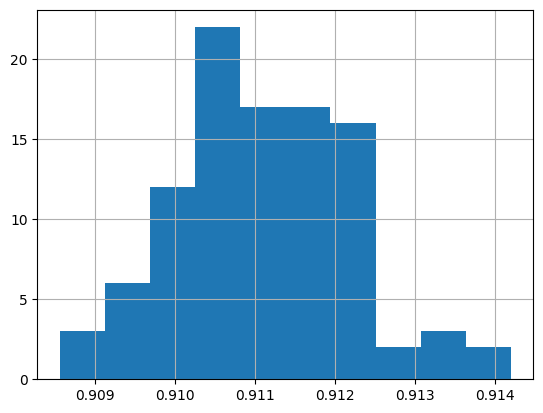

In [ ]:
pd.Series(balanced_df_results).hist() ;

What do you notice about the distribution of accuracy scores?

There is a negative skew.

#### Confusion Matrix and Heatmap

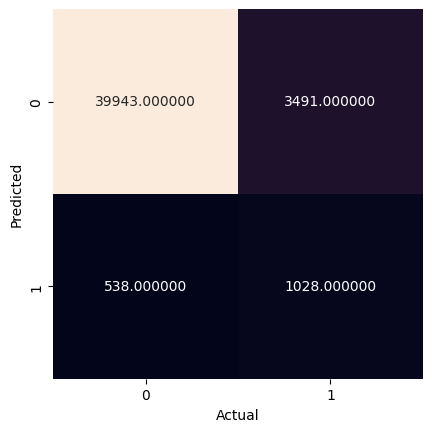

In [ ]:
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
)
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Classification Report

In [ ]:
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95     40481
           1       0.66      0.23      0.34      4519

    accuracy                           0.91     45000
   macro avg       0.79      0.61      0.64     45000
weighted avg       0.89      0.91      0.89     45000



What do you notice? That is, how do the different metrics compare to each other?

## Data Visualization/Communication of Results


### Data Visualization

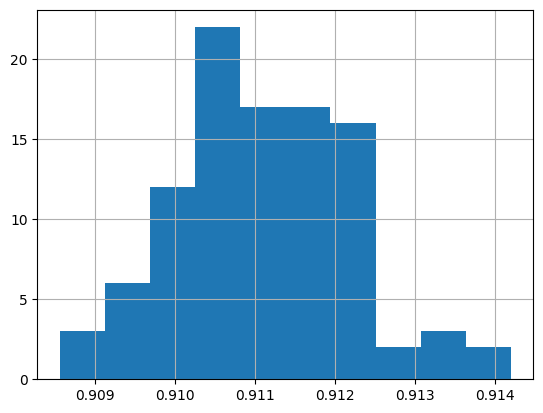

In [ ]:
# Display a histagram of the results
pd.Series(balanced_df_results).hist() ;

### Conclusion

- Using all var columns and balancing the dataset gave us 91% accuracy, same as with previous Pass-05
- Bad at predicting no-transactions
- OK at predicting a successful transaction
- Low false positive (we predict customer will make a transaction but customer does not)
- High false negative (we predict customer will not make a transaction but customer does)

### Future work


- For Pass-07,
  - Use big dataset
  - Use only the first 15 columns
  - Use ony the first 10,000 rows